# CatBoost for classification

[Master Tree Ensemble Models course](https://www.trainindata.com/p/master-tree-ensemble-models)

In this notebook, we train CatBoost to predict which clients subscribe to a term deposit. We pass the categorical variables as they are, so that CatBoost encodes them, train with early stopping, then compare ordered and plain boosting at several depths, compare the bootstrap types, and look at how the combinations of categorical variables change the model. Then, we save and load the model and continue an interrupted training from a snapshot with a smaller learning rate. Finally, we look at the feature importance.

CatBoost's classes, `CatBoostClassifier` and `CatBoostRegressor`, follow the scikit-learn interface, so they fit into scikit-learn pipelines and searches. They are also the full API of the library, so we use them in this course.

In [1]:
import pathlib
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split

### Load data

We use the bank marketing data that we prepared in the notebook of the folder prepare-data.

In [2]:
df = pd.read_csv("../prepare-data/bank_marketing.csv")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,NaN,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,NaN,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,NaN,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,NaN,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,NaN,0,unknown,0


In [3]:
# CatBoost encodes the categories by itself, so we keep the strings instead of integers
cat_features = list(df.select_dtypes("str").columns)

# CatBoost takes missing values in the numerical variables, so we leave NaN as it is

cat_features

['job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'poutcome']

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns="y"),
    df["y"],
    test_size=0.3,
    stratify=df["y"],
    random_state=0,
)

X_train.shape, X_test.shape

((31647, 16), (13564, 16))

In [5]:
# the fraction of clients that subscribe to the term deposit
y_train.mean(), y_test.mean()

(np.float64(0.11697791259835055), np.float64(0.1170008846947803))

### Prepare the data for CatBoost

CatBoost's own data container is the `Pool`, which holds the features, the target and the names of the categorical variables. We build one for the train set and one for the test set, and reuse them in the rest of the notebook.

In [6]:
train_pool = Pool(X_train, y_train, cat_features=cat_features)
test_pool = Pool(X_test, y_test, cat_features=cat_features)

train_pool.shape, test_pool.shape

((31647, 16), (13564, 16))

### Train the model with the default parameters

We show the hyperparameters with their default values, so that we can see the effect of changing them later on.

We leave out the learning rate, which CatBoost chooses from the data, and `l2_leaf_reg`: as we saw in the lectures on hyperparameters, setting it, even at its default of 3, turns off the automatic learning rate, which then falls back to 0.03. We set the number of trees, `iterations`, when we train.

We stop early on the roc-auc instead of the default logloss, and the hint `skip_train~false` adds it on the train set, so that we can plot both curves.

In [7]:
params = {
    # learning task
    "loss_function": "Logloss",
    "eval_metric": "AUC:hints=skip_train~false",  # the hint adds roc-auc on the train set

    # tree structure and algorithm
    "boosting_type": "Plain",        # the default on CPU; on GPU, Ordered up to 50,000 rows
    "grow_policy": "SymmetricTree",  # oblivious trees
    "has_time": False,               # random permutations, not the order of the rows
    "depth": 6,

    # categorical features
    "one_hot_max_size": 2,           # one-hot up to this many values, target statistics above
    "max_ctr_complexity": 4,         # most variables in one combination

    # sampling
    "bootstrap_type": "MVS",         # the default on CPU; Bayesian on GPU
    "subsample": 0.8,                # share of the rows for each tree, the default with MVS
    "bagging_temperature": 1,        # Bayesian only

    # feature processing
    "border_count": 254,             # the default on CPU; 128 on GPU
    "feature_border_type": "GreedyLogSum",
    "nan_mode": "Min",               # missing values go to the far left

    # hardware and reproducibility
    "task_type": "CPU",
    "thread_count": 4,               # fixed, so that the timings are comparable
    "random_seed": 0,
    "allow_writing_files": False,    # no catboost_info folder next to the notebook
}

We let CatBoost add up to 2000 trees, and with `early_stopping_rounds=50` the training stops when the roc-auc in the test set has not improved for 50 rounds. Here, to keep the notebook short, the test set plays the role of the validation set. In a real project, we would hold out a separate validation set, because choosing the number of trees on the test set makes the test score optimistic.

In [8]:
model = CatBoostClassifier(**params, iterations=2000).fit(
    train_pool,
    eval_set=test_pool,
    early_stopping_rounds=50,
    verbose=50,
)

Learning rate set to 0.055023


0:	learn: 0.8600524	test: 0.8582790	best: 0.8582790 (0)	total: 288ms	remaining: 9m 35s


50:	learn: 0.9259142	test: 0.9236603	best: 0.9236603 (50)	total: 5.71s	remaining: 3m 38s


100:	learn: 0.9344417	test: 0.9290740	best: 0.9290740 (100)	total: 11.1s	remaining: 3m 28s


150:	learn: 0.9388752	test: 0.9313213	best: 0.9313213 (150)	total: 17.6s	remaining: 3m 36s


200:	learn: 0.9422116	test: 0.9325677	best: 0.9325677 (200)	total: 24.2s	remaining: 3m 36s


... (9 outputs left out)

700:	learn: 0.9625719	test: 0.9367441	best: 0.9367730 (690)	total: 1m 32s	remaining: 2m 51s


750:	learn: 0.9640171	test: 0.9368360	best: 0.9368598 (720)	total: 1m 39s	remaining: 2m 46s


800:	learn: 0.9651308	test: 0.9368889	best: 0.9369029 (787)	total: 1m 47s	remaining: 2m 40s


Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.9369029034
bestIteration = 787

Shrink model to first 788 iterations.


In [9]:
# get_best_iteration() counts from 0, so the best model has one tree more
num_rounds = model.get_best_iteration() + 1

print(f"best number of trees: {num_rounds}, trees in the model: {model.tree_count_}")

best number of trees: 788, trees in the model: 788


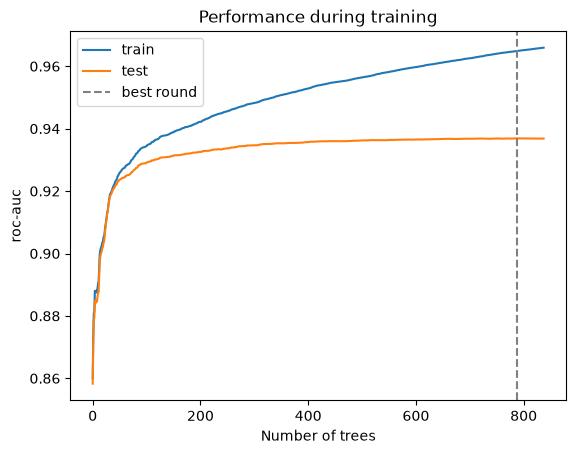

In [10]:
evals_result = model.get_evals_result()

plt.plot(evals_result["learn"]["AUC"], label="train")
plt.plot(evals_result["validation"]["AUC"], label="test")
plt.axvline(model.get_best_iteration(), color="grey", linestyle="dashed", label="best round")
plt.xlabel("Number of trees")
plt.ylabel("roc-auc")
plt.title("Performance during training")
plt.legend()
plt.show()

The test roc-auc reached its best value with 788 trees, and early stopping trained 50 more rounds before it gave up. CatBoost drops those extra rounds and returns a model with 788 trees, because `use_best_model` is on by default when we pass an eval set.

In [11]:
def evaluate(model, train_pool, y_train, test_pool, y_test):
    for name, data, y in [("train", train_pool, y_train), ("test", test_pool, y_test)]:
        # the second column is the probability of a subscription
        probabilities = model.predict_proba(data)[:, 1]
        balanced_accuracy = balanced_accuracy_score(y, probabilities > 0.5)
        roc_auc = roc_auc_score(y, probabilities)
        print(f"{name} balanced accuracy: {balanced_accuracy:.4f}, roc-auc: {roc_auc:.4f}")


evaluate(model, train_pool, y_train, test_pool, y_test)

train balanced accuracy: 0.7998, roc-auc: 0.9607
test balanced accuracy: 0.7448, roc-auc: 0.9369


The test roc-auc of 0.937 is higher than the 0.921 of the gradient boosting machine with the default parameters in the previous section. The roc-auc tells us how well the model ranks the clients, independently of the threshold, so we use it to compare the models in the rest of the notebook.

`get_all_params()` returns every parameter of the trained model, including the ones that CatBoost chose by itself.

In [12]:
all_params = model.get_all_params()

pd.Series({name: all_params[name] for name in ["learning_rate", "boosting_type", "bootstrap_type", "subsample"]})

learning_rate     0.055023
boosting_type        Plain
bootstrap_type         MVS
subsample              0.8
dtype: object

With 2000 rounds, 31647 rows and an eval set, CatBoost chose a learning rate of about 0.055.

Let's now change one hyperparameter at a time to understand what is going on.

CatBoost chooses the learning rate from the number of rounds, the number of rows and whether there is an eval set, so we fix the one that it chose for the default model.

In [13]:
fixed_params = {**params, "learning_rate": all_params["learning_rate"]}


def timed_train(params, pool, num_rounds):
    start = time.perf_counter()
    model = CatBoostClassifier(**params, iterations=num_rounds).fit(pool, verbose=False)
    return model, time.perf_counter() - start

In [14]:
def scores(model, train_pool, y_train, test_pool, y_test):
    probabilities = model.predict_proba(test_pool)[:, 1]
    return {
        "train roc-auc": roc_auc_score(y_train, model.predict_proba(train_pool)[:, 1]),
        "test roc-auc": roc_auc_score(y_test, probabilities),
        "test balanced accuracy": balanced_accuracy_score(y_test, probabilities > 0.5),
    }

### Ordered or plain boosting by depth

We saw in the lecture on prediction shift that plain boosting computes the gradient of each row with a model that has already seen that row, and in the lecture on ordered boosting that CatBoost avoids this by taking each gradient from a model fitted on earlier rows only. A deeper tree fits the rows that it was trained on more closely, so the prediction shift of plain boosting should grow with the depth. Ordered boosting does more work for each tree, so we compare the two boosting types with a `depth` from 2 to 10, on the test score and on the time.

The depth changes how many trees the model needs, so here every setting trains 2000 rounds with the test set as eval set, and CatBoost keeps the best round, as it did for the default model. We do not stop early, so that every setting trains the same rounds. The times depend on the machine, so we should read them relative to each other.

In [15]:
results = {}
for depth in [2, 4, 6, 8, 10]:
    for boosting_type in ["Plain", "Ordered"]:
        start = time.perf_counter()
        fitted = CatBoostClassifier(**{**fixed_params, "depth": depth, "boosting_type": boosting_type}, iterations=2000).fit(
            train_pool, eval_set=test_pool, verbose=False
        )
        seconds = time.perf_counter() - start
        results[(depth, boosting_type)] = {
            "trees": fitted.tree_count_,
            "seconds": seconds,
            **scores(fitted, train_pool, y_train, test_pool, y_test),
        }

depth_results = pd.DataFrame(results).T.astype({"trees": int})
depth_results.index.names = ["depth", "boosting"]
depth_results.round(4)

trees    seconds  train roc-auc  test roc-auc  \
depth boosting                                                  
2     Plain      2000    99.4452         0.9391        0.9318   
      Ordered    2000   133.7796         0.9369        0.9303   
4     Plain      1652   180.9543         0.9544        0.9363   
      Ordered    1640   254.2384         0.9494        0.9357   
6     Plain       788   278.8163         0.9607        0.9369   
      Ordered    2000   376.4033         0.9577        0.9365   
8     Plain       332   374.4910         0.9624        0.9362   
      Ordered     677   589.2991         0.9515        0.9363   
10    Plain       256   603.5805         0.9740        0.9358   
      Ordered     976  1471.1447         0.9586        0.9375   

                test balanced accuracy  
depth boosting                          
2     Plain                     0.7238  
      Ordered                   0.7214  
4     Plain                     0.7482  
      Ordered                   0.7385  
6     Plain                     0.7448  
      Ordered                   0.7487  
8     Plain                     0.7351  
      Ordered                   0.7422  
10    Plain                     0.7369  
      Ordered                   0.7494

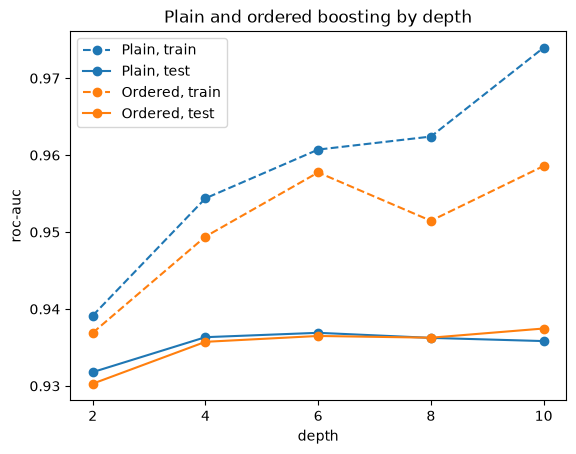

In [16]:
for boosting_type, color in [("Plain", "C0"), ("Ordered", "C1")]:
    rows = depth_results.xs(boosting_type, level="boosting")
    plt.plot(rows.index, rows["train roc-auc"], marker="o", color=color, linestyle="dashed", label=f"{boosting_type}, train")
    plt.plot(rows.index, rows["test roc-auc"], marker="o", color=color, label=f"{boosting_type}, test")
plt.xticks([2, 4, 6, 8, 10])
plt.xlabel("depth")
plt.ylabel("roc-auc")
plt.title("Plain and ordered boosting by depth")
plt.legend()
plt.show()

At the default depth of 6, ordered boosting lowers the test roc-auc a little, from 0.9369 to 0.9365, and it is slower at every depth. Plain boosting peaks at depth 6 while its train roc-auc keeps growing, and ordered boosting reaches its best test roc-auc, 0.9375, with depth 10, only 0.0006 above the best plain model, so plain boosting with the default depth remains a good choice here.

### Bootstrap type

We saw in the lectures on hyperparameters that MVS, the default `bootstrap_type`, keeps the rows with the largest gradients and samples the rest, while the Bayesian bootstrap drops no row and gives each row a random weight, which grows more uneven as `bagging_temperature` rises. We compare MVS with no sampling and with the Bayesian bootstrap at a temperature of 0, 1 and 10. Every setting trains the number of trees that early stopping found, so that differences in time come from the setting and not from the number of trees.

In [17]:
# CatBoost rejects subsample with No and Bayesian, and bagging_temperature with No
bootstrap_params = {
    name: value for name, value in fixed_params.items() if name not in ["subsample", "bagging_temperature"]
}
bootstrap_settings = {
    "No": {"bootstrap_type": "No"},
    "MVS": {"bootstrap_type": "MVS", "subsample": 0.8},
    "Bayesian, temperature 0": {"bootstrap_type": "Bayesian", "bagging_temperature": 0},
    "Bayesian, temperature 1": {"bootstrap_type": "Bayesian", "bagging_temperature": 1},
    "Bayesian, temperature 10": {"bootstrap_type": "Bayesian", "bagging_temperature": 10},
}

In [18]:
results = {}
for name, setting in bootstrap_settings.items():
    fitted, seconds = timed_train({**bootstrap_params, **setting}, train_pool, num_rounds)
    results[name] = {"seconds": seconds, **scores(fitted, train_pool, y_train, test_pool, y_test)}

pd.DataFrame(results).T.round(4)

,seconds,train roc-auc,test roc-auc,test balanced accuracy
No,114.5664,0.9610,0.9369,0.7474
MVS,110.4845,0.9607,0.9369,0.7448
"Bayesian, temperature 0",111.5276,0.9610,0.9369,0.7474
"Bayesian, temperature 1",111.6598,0.9600,0.9357,0.7405
"Bayesian, temperature 10",112.7548,0.9499,0.9279,0.7086


With the same 788 trees, the Bayesian bootstrap with a temperature of 0 gives exactly the scores of no sampling, because every weight is 1. As the temperature rises, the test roc-auc falls, from 0.9369 to 0.9357 with a temperature of 1 and to 0.9279 with 10. MVS, the default, also reaches 0.9369, and the times in the table differ little, so we keep the default.

### Combinations of categorical variables

We saw in the lecture on feature combinations that CatBoost combines categorical variables greedily while it builds each tree, and computes target statistics on the combinations as well. `max_ctr_complexity` is the largest number of variables in one combination, so 1 means no combinations at all. We train with 1 to 4.

In [19]:
results = {}
for complexity in [1, 2, 3, 4]:
    fitted, seconds = timed_train({**fixed_params, "max_ctr_complexity": complexity}, train_pool, num_rounds)
    results[complexity] = {"seconds": seconds, **scores(fitted, train_pool, y_train, test_pool, y_test)}

pd.DataFrame(results).T.round(4)

,seconds,train roc-auc,test roc-auc,test balanced accuracy
1,94.1573,0.9648,0.9356,0.7353
2,106.2280,0.9613,0.9363,0.7373
3,109.3639,0.9600,0.9367,0.7491
4,108.6294,0.9607,0.9369,0.7448


With the same 788 trees, combining categorical variables barely changes the test roc-auc on this data: it goes from 0.9356 without combinations to 0.9369 with up to 4 variables in a combination. The model without combinations trains fastest.

## Callbacks and model IO

### Callbacks

A callback is an object with an `after_iteration` method, which CatBoost calls after every tree with the index of the round and the metrics up to that round; when the method returns False, the training stops. The callback does not receive the model, so it can neither save the model nor change the learning rate, and CatBoost has no learning-rate schedule.

CatBoost has no built-in callbacks either; arguments of `fit` do their work: `early_stopping_rounds` stops the training early, `verbose` prints the log every so many rounds, as in the training of the default model, and `save_snapshot` saves the state of the training, which we use below. So we write no callback here.

### Save and load the model

We save the model in CatBoost's binary format, which holds the trees and the target statistics of the categorical variables, and load it into a new model.

In [20]:
model.save_model("catboost-classification.cbm")
loaded = CatBoostClassifier().load_model("catboost-classification.cbm")

np.array_equal(model.predict_proba(test_pool), loaded.predict_proba(test_pool))

True

### Continue the training

While it trains, CatBoost can save its progress in a snapshot. With `save_snapshot=True`, `fit` writes the state of the training to `snapshot_file` every `snapshot_interval` seconds, 600 by default, and once more when the training ends. A snapshot is a training state, not a model that can predict. When we resume from it, most parameters must stay the same; here, we raise the number of rounds and lower the learning rate. To start a new training on top of a saved model with other parameters, `fit` takes that model in `init_model` instead.

CatBoost refuses `save_snapshot` when it may not write files, so for these two models we allow it and send its files to the folder `checkpoints/classification` with `train_dir`. `snapshot_params` starts from `fixed_params` and fixes the leaf estimation of the default model.

The snapshot records how far the training got, and `iterations` sets how far it should go. Here, we imitate an interruption by training 50 of the planned 150 rounds.

In [21]:
checkpoints = pathlib.Path("checkpoints") / "classification"
checkpoints.mkdir(parents=True, exist_ok=True)
# a snapshot of an earlier run would make the training continue from there
(checkpoints / "snapshot").unlink(missing_ok=True)

snapshot_params = {
    **fixed_params,
    # the leaf estimation of the default model, which CatBoost changes below 200 rounds
    "leaf_estimation_iterations": all_params["leaf_estimation_iterations"],
    "allow_writing_files": True,
    "train_dir": str(checkpoints),
}

In [22]:
interrupted = CatBoostClassifier(**snapshot_params, iterations=50).fit(
    train_pool,
    eval_set=test_pool,
    # keep every tree; with an eval set, CatBoost would cut the model to the best round
    use_best_model=False,
    verbose=50,
    save_snapshot=True,
    snapshot_file="snapshot",
)

interrupted.tree_count_

0:	learn: 0.8600524	test: 0.8582790	best: 0.8582790 (0)	total: 134ms	remaining: 6.55s


49:	learn: 0.9255985	test: 0.9234987	best: 0.9234987 (49)	total: 6.81s	remaining: 0us

bestTest = 0.9234986939
bestIteration = 49



50

We run `fit` again with the same snapshot file, 150 rounds and a smaller learning rate of 0.05; the log continues from round 50.

In [23]:
resumed = CatBoostClassifier(**{**snapshot_params, "learning_rate": 0.05}, iterations=150).fit(
    train_pool,
    eval_set=test_pool,
    use_best_model=False,
    verbose=25,
    save_snapshot=True,
    snapshot_file="snapshot",
)

print(f"trees before: {interrupted.tree_count_}, trees after: {resumed.tree_count_}")

50:	learn: 0.9258884	test: 0.9236472	best: 0.9236472 (50)	total: 6.95s	remaining: 13.5s


75:	learn: 0.9299692	test: 0.9259238	best: 0.9259238 (75)	total: 10.4s	remaining: 10.3s


100:	learn: 0.9342770	test: 0.9286215	best: 0.9286215 (100)	total: 14s	remaining: 6.91s


125:	learn: 0.9366846	test: 0.9299445	best: 0.9299445 (125)	total: 17.5s	remaining: 3.36s


149:	learn: 0.9385591	test: 0.9308594	best: 0.9308594 (149)	total: 20.8s	remaining: 0us

bestTest = 0.9308594466
bestIteration = 149

trees before: 50, trees after: 150


In [24]:
evaluate(resumed, train_pool, y_train, test_pool, y_test)

train balanced accuracy: 0.7298, roc-auc: 0.9384
test balanced accuracy: 0.7147, roc-auc: 0.9309


Starting from the 50 trees of the snapshot, the 100 new trees with a learning rate of 0.05 bring the test roc-auc to 0.9309, below the 0.9369 of the default model with 788 trees.

## Feature importance

We saw in the lecture on feature importance that XGBoost summarizes the splits of each feature as weight, gain and cover. CatBoost's default type, `PredictionValuesChange`, also comes from the trees alone: for every split on a feature, it compares the leaves that differ only in that split and adds up the squared distances of their values from their weighted average, weighted by the number of training rows in each leaf. The features add up to 100. It is closest to a total gain, but it measures the change of the predictions, not of the loss.

CatBoost also offers `LossFunctionChange`, which measures on a dataset how much the loss grows without each feature, and types that explain single predictions, such as `ShapValues`; we do not use them here. We plot the features from the most to the least important.

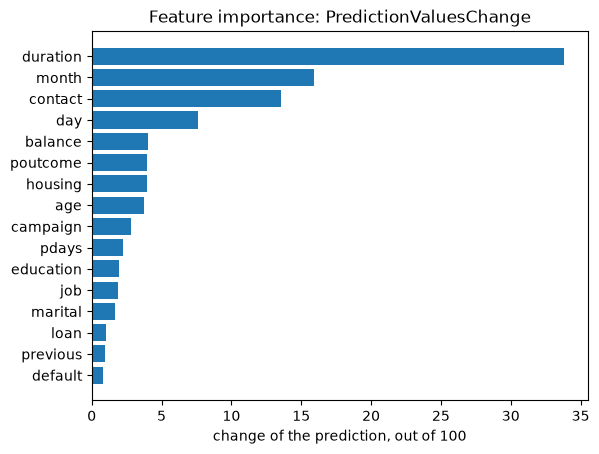

In [25]:
prediction_change = pd.Series(
    model.get_feature_importance(type="PredictionValuesChange"),
    index=model.feature_names_,
).sort_values(ascending=False)

# the most important feature on top
plt.barh(prediction_change.index[::-1], prediction_change.values[::-1])
plt.xlabel("change of the prediction, out of 100")
plt.title("Feature importance: PredictionValuesChange")
plt.show()

By `PredictionValuesChange`, `duration`, the length of the last call, is by far the most important feature, with 34 of the 100 points, followed by `month` and `contact`. With `day`, these four features about the last call hold about 71 of the 100 points, and the features about the client, such as `balance` and `age`, come after them.